In [7]:
import numpy as np
import pandas as pd
from matplotlib import pyplot
import os

import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import plot_util as putil
import multi_fgl_utils as util
import dio3

In [13]:
plots_folder = '../plots/comparisons/'
paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper\
/cov_shift_paper_main/plots/'
save_plots = 1
save_png = 0
copy2tex = 1
rel_std = 1

folder = '../results/4FGL-DR3_probabilistic_classification_weighted/'
cat_fn = folder + '4FGL-DR3_6class_GMM_nmin100_prob_cat.csv'
cat_info_fn = folder + '4FGL-DR3_6class_GMM_nmin100_summary.csv'
wcat_fn = folder + '4FGL-DR3_6class_GMM_nmin100_weighted_prob_cat.csv'

cat = pd.read_csv(cat_fn, index_col=0)
cat_info = pd.read_csv(cat_info_fn, index_col=0, dtype=str)
wcat = pd.read_csv(wcat_fn, index_col=0)
cats = {'weighted': wcat, 'unweighted': cat}
compare1 = [['weighted', 'RF'], ['unweighted', 'RF']]
compare2 = [['weighted', 'NN'], ['unweighted', 'NN']]
compare3 = [['unweighted', 'RF'], ['unweighted', 'NN']]
compare4 = [['weighted', 'RF'], ['weighted', 'NN']]
wlabel = {'weighted': 'w', 'unweighted': ''}

nsrc_fn = '../data_out/nsrc_dict.yaml'
nsrc_dict = dio3.loaddict(nsrc_fn)
nsrc_df = util.nsrc_dict2df(nsrc_dict)

#show = [compare1, compare4]
#show = [compare3, compare4]
show = [compare1, compare2, compare3, compare4]
single_plot_pars = {}


In [14]:
nrows = 2
ncols = 3
fig_height = 3 * nrows + 2   # height in inches
fig_width = 3 * ncols + 6  # width in inches
#all_plots_pars = {'axes.titlesize':18}
all_plots_pars = {'bottom':0.07, 'left':0.12, 'right':0.97, 'top':0.97}
all_plots_pars.update({'axes.labelsize': 14,
                      'axes.titlesize': 14,  #title
                      'legend.fontsize': 10,
                      'xtick.labelsize':12, #ticks
                      'ytick.labelsize':12,}
                     )
fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
#all_plots_pars['font.size'] = 11
#all_plots_pars['legend.fontsize'] = 10

putil.setup_figure_pars(pars_dict=all_plots_pars)
#putil.setup_figure_pars(pars_dict=single_plot_pars)

0

In [15]:
nodes = range(1, 7)

In [16]:
cat.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1', '1_RF',
       '1_RF_std', '1_NN', '1_NN_std', '2_RF', '2_RF_std', '2_NN', '2_NN_std',
       '3_RF', '3_RF_std', '3_NN', '3_NN_std', '4_RF', '4_RF_std', '4_NN',
       '4_NN_std', '5_RF', '5_RF_std', '5_NN', '5_NN_std', '6_RF', '6_RF_std',
       '6_NN', '6_NN_std', 'sample_weight'],
      dtype='object')

save figure to file: ../plots/comparisons//prob_comparisons_rel.pdf
cp ../plots/comparisons//prob_comparisons_rel.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper/cov_shift_paper_main/plots//prob_comparisons_rel.pdf


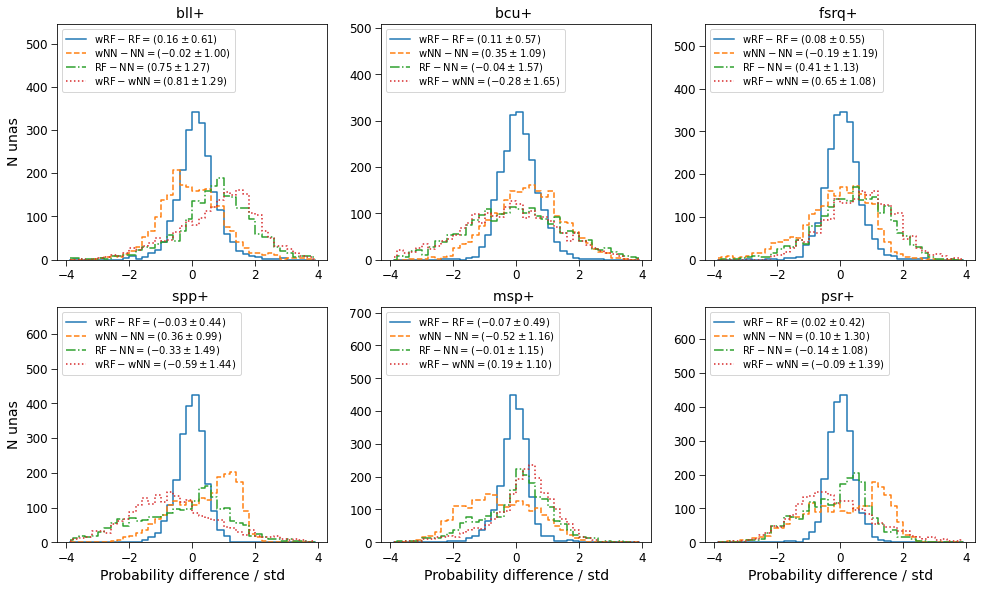

In [17]:
epsilon = 1.e-15
unas_mask = (cat['CLASS1'] == 'unas')
if rel_std:
    maxv = 4
    npts = int(maxv * 10) + 1
    bins = np.linspace(-maxv, maxv, npts)
else:
    maxv = 0.4
    bins = np.linspace(-maxv, maxv, 41)
xs = (bins[1:] + bins[:-1]) / 2.

lss = ['-', '--', '-.', ':']

pyplot.figure()
for ind, node in enumerate(nodes[:]):
    vmax = 0.
    classes = cat_info['Physical classes'].loc[node].split(', ')
    max_class = util.get_max_class(classes, nsrc_df)
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    for ic, comp in enumerate(show):
        vs = []
        stds = []
        label = r'$\rm '
        for i in range(2):
            if i == 1:
                label += ' - '
            cat_name, alg = comp[i]
            clm = '%i_%s' % (node, alg)
            vs.append(cats[cat_name][clm][unas_mask])
            stds.append(cats[cat_name][clm + '_std'][unas_mask])
            label += '%s%s' % (wlabel[cat_name], alg)
        pvs = vs[0] - vs[1]
        if rel_std:
            std_av = np.sqrt(stds[0]**2 + stds[1]**2) / np.sqrt(2.) + epsilon
            pvs /= std_av
            label += ' = (%.2f \pm %.2f)$' % (np.mean(pvs), np.std(pvs))
        else:
            #label += ' = (%.2f \pm %.2f)\%%$' % (np.mean(pvs)*100, np.std(pvs)*100)
            if np.around(np.mean(pvs)*1000) == 0.:
                label += ' = (%.2f \pm %.2f)\\times 10^{-2}$' % (np.mean(pvs)*100, np.std(pvs)*100)
            else:
                label += ' = (%.1f \pm %.1f)\\times 10^{-2}$' % (np.mean(pvs)*100, np.std(pvs)*100)
        label = label.replace('_', '\\_')
        hvs = np.histogram(pvs, bins=bins)[0]
        vmax = np.maximum(vmax, np.max(hvs))
        pyplot.plot(xs, hvs, drawstyle='steps-mid', ls=lss[ic%len(lss)], label=label)
    #pyplot.legend(fontsize=12, labelspacing=0.3, loc='upper left')
    pyplot.legend(labelspacing=0.1, loc='upper left')
    pyplot.title('%s+ ' % max_class)
    pyplot.ylim(0, vmax*1.6)
    if ind >= ncols * (nrows - 1):
        if rel_std:
            pyplot.xlabel('Probability difference / std')
        else:
            pyplot.xlabel('Probability difference')
        
    if ind < ncols * (nrows - 1) and False:
        ax.axes.xaxis.set_visible(False)
    if ind % ncols != 0 and False:
        ax.axes.yaxis.set_visible(False)
    if ind % ncols == 0:
        pyplot.ylabel('N unas')


if save_plots:
    fn = '%s/prob_comparisons.pdf' % (plots_folder)
    if rel_std:
        fn = '%s/prob_comparisons_rel.pdf' % (plots_folder)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)
